
# Predicting missed outpatient appointments

This notebook ranks booked visits by the chance they will be missed. The operational question is not a single accuracy number. A reminder can be sent to someone who would have attended. Double-booking that same person puts two patients in one slot and crowds the waiting room.

The extract is the public Vitória, Brazil appointment file (110,527 rows). It is not an African facility file. Comparable open microdata were not available, and the written report treats the geography as a limit on deployment. `No-show = Yes` in the source file means the patient did **not** attend. That is the positive class.

Set `RETRAIN = False` to read the saved metrics and figures. Set it to `True` to fit all sixteen models again.

On a local checkout, run this notebook from the repository root so `src/` is next to it. Google Colab opens the `.ipynb` by itself and does not bring `src/clinic_noshow` along. `GITHUB_REPO_URL` in the first cell points at the public GitHub repository, and the facilitator’s Colab session clones the rest of the project. `DRIVE_CODE_ZIP_URL` is the alternative: a zip of this repository shared as “Anyone with the link can view”. Mounting My Drive only sees files already in that Google account, so a shared folder has to be downloaded by that link or copied into My Drive first (`DRIVE_PROJECT_FOLDER`).


In [ ]:

from pathlib import Path
import os
import subprocess
import sys

# Fill these in before submission. Leave a line blank to skip that option.
# GitHub must be the repository that contains src/clinic_noshow.
GITHUB_REPO_URL = "https://github.com/sammyn11/Clinic-appointment-no-show-classification.git"
# Public Drive link to a zip of the same repository (File → Share → Anyone with the link).
DRIVE_CODE_ZIP_URL = ""
# Folder name inside My Drive, after the shared project has been copied into this account.
DRIVE_PROJECT_FOLDER = ""


def _usable(url: str) -> str:
    text = url.strip()
    if not text or "REPLACE_WITH" in text:
        return ""
    return text


def _has_package(folder: Path) -> bool:
    return (folder / "src" / "clinic_noshow" / "__init__.py").is_file()


def _find_existing() -> Path | None:
    seeds = [Path.cwd(), Path("/content")]
    content = Path("/content")
    if content.is_dir():
        seeds.extend(path for path in content.iterdir() if path.is_dir())
    seen: set[Path] = set()
    for seed in seeds:
        for candidate in (seed, *seed.parents):
            if candidate in seen:
                continue
            seen.add(candidate)
            if _has_package(candidate):
                return candidate
    return None


def _clone_github(url: str) -> Path:
    destination = Path("/content/clinic-noshow")
    if not _has_package(destination):
        if destination.exists():
            import shutil
            shutil.rmtree(destination)
        subprocess.check_call(["git", "clone", "--depth", "1", url, str(destination)])
    if not _has_package(destination):
        raise FileNotFoundError(f"Cloned {url} but src/clinic_noshow was not in it.")
    return destination


def _download_drive_zip(url: str) -> Path:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
    import gdown
    import zipfile

    zip_path = Path("/content/clinic-noshow-code.zip")
    gdown.download(url, str(zip_path), quiet=False, fuzzy=True)
    destination = Path("/content/clinic-noshow-drive")
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(destination)
    if _has_package(destination):
        return destination
    for child in destination.iterdir():
        if child.is_dir() and _has_package(child):
            return child
    raise FileNotFoundError("The Drive zip did not contain src/clinic_noshow.")


def _mount_drive_folder(folder_name: str) -> Path:
    from google.colab import drive

    drive.mount("/content/drive")
    root = Path("/content/drive/MyDrive")
    direct = root / folder_name
    if _has_package(direct):
        return direct
    for child in root.iterdir():
        nested = child / folder_name
        if _has_package(child) and child.name == folder_name:
            return child
        if _has_package(nested):
            return nested
    raise FileNotFoundError(
        f"My Drive has no folder named {folder_name} containing src/clinic_noshow. "
        "Add a shortcut to the shared folder, or copy the project into My Drive."
    )


ROOT = _find_existing()
if ROOT is None and _usable(GITHUB_REPO_URL):
    ROOT = _clone_github(_usable(GITHUB_REPO_URL))
if ROOT is None and _usable(DRIVE_CODE_ZIP_URL):
    ROOT = _download_drive_zip(_usable(DRIVE_CODE_ZIP_URL))
if ROOT is None and DRIVE_PROJECT_FOLDER.strip():
    ROOT = _mount_drive_folder(DRIVE_PROJECT_FOLDER.strip())
if ROOT is None:
    raise FileNotFoundError(
        "This Colab session has the notebook and not the training package. "
        "Paste the public GitHub repository into GITHUB_REPO_URL, or a public "
        "Drive zip link into DRIVE_CODE_ZIP_URL, then run this cell again."
    )

os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

missing = []
for module_name, pip_name in (
    ("pandas", "pandas"),
    ("sklearn", "scikit-learn"),
    ("tensorflow", "tensorflow"),
    ("matplotlib", "matplotlib"),
    ("joblib", "joblib"),
):
    try:
        __import__(module_name)
    except Exception:
        missing.append(pip_name)
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import pandas as pd

from clinic_noshow.config import FIG_DIR, METRIC_DIR, SEED
from clinic_noshow.preprocess import prepare_dataset

RETRAIN = False
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)
print("seed", SEED)
print("root", ROOT)


## Data, cleaning, and the patient split

Lead time is the calendar gap between the appointment date and the booking in Vitória civil time (UTC−3). Using the raw timestamps would mark same-day afternoon bookings as negative waits, because the appointment column is stored at midnight. History features use only earlier visits of the same patient. Neighbourhood target encoding is fit on training patients, out of fold, so a visit does not help build the code applied to itself.

The split is by patient. A random row split would let a later training row use an earlier test row's outcome.

In [2]:
data = prepare_dataset()
profile = data.profile
keep = [
    "n_raw", "n_clean", "n_removed_age", "n_removed_negative_lead",
    "n_patients", "noshow_rate", "appointment_min", "appointment_max",
    "scheduled_min", "scheduled_max", "n_neighbourhoods",
    "same_day_rate", "median_lead_days", "sms_rate_same_day", "sms_rate_later",
    "n_train", "n_val", "n_test",
    "train_noshow_rate", "val_noshow_rate", "test_noshow_rate",
]
for key in keep:
    value = profile[key]
    if isinstance(value, float):
        value = round(value, 4)
    print(f"{key:28} {value}")

overlap = set(data.train.PatientId) & set(data.test.PatientId)
assert not overlap, overlap
print("patient ids overlap train/test:", bool(overlap))

show_cols = [
    "age", "gender_male", "lead_days", "same_day", "sms_received",
    "prior_appt_count", "prior_noshow_rate", "is_first_appt",
    "neighbourhood_te", "noshow",
]
data.train[show_cols].head(8)

n_raw                        110527
n_clean                      110516
n_removed_age                6
n_removed_negative_lead      5
n_patients                   62296
noshow_rate                  0.2019
appointment_min              2016-04-29
appointment_max              2016-06-08
scheduled_min                2015-11-10
scheduled_max                2016-06-08
n_neighbourhoods             81
same_day_rate                0.3489
median_lead_days             4.0
sms_rate_same_day            0.0
sms_rate_later               0.4931
n_train                      77054
n_val                        16736
n_test                       16726
train_noshow_rate            0.2019
val_noshow_rate              0.2025
test_noshow_rate             0.201
patient ids overlap train/test: False


,age,gender_male,lead_days,same_day,sms_received,prior_appt_count,prior_noshow_rate,is_first_appt,neighbourhood_te,noshow
0,44,0,3,0,0,0,0.201936,1,0.224598,0
1,39,1,0,1,0,0,0.201936,1,0.207134,0
2,33,0,0,1,0,0,0.201936,1,0.212659,0
3,12,1,3,0,0,0,0.201936,1,0.167212,0
4,14,0,7,0,1,0,0.201936,1,0.190844,0
6,16,1,0,1,0,0,0.201936,1,0.186456,0
7,22,0,19,0,1,0,0.201936,1,0.181497,0
8,23,0,21,0,1,1,0.000000,0,0.181497,0


### What that profile is saying

About one visit in five is a no-show, so a classifier that always predicts attendance is roughly 80 percent accurate and useless. Same-day bookings are about a third of the rows, and no SMS was sent on those rows. Messages went out on about half of the later visits. Any model that is not given lead time will confuse the message with the wait.

The three no-show rates across splits sit within a few tenths of a percent of each other. That is the check that the patient stratification did not dump every frequent no-show into one fold.

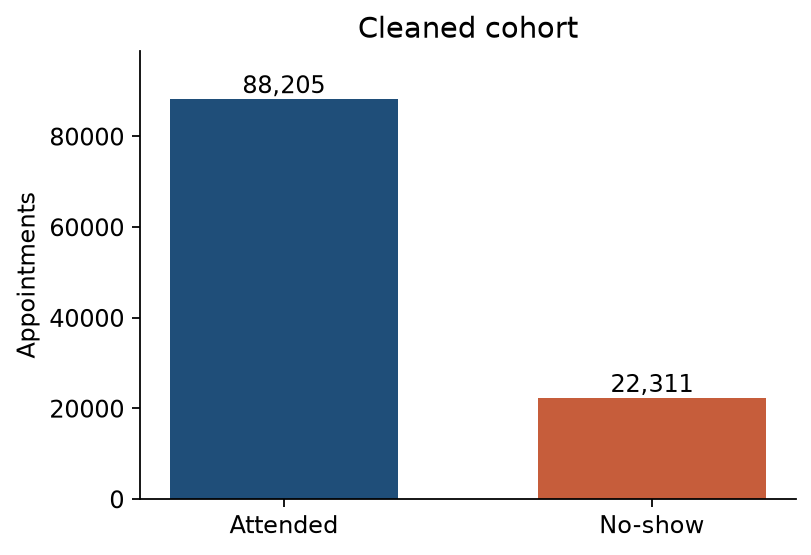

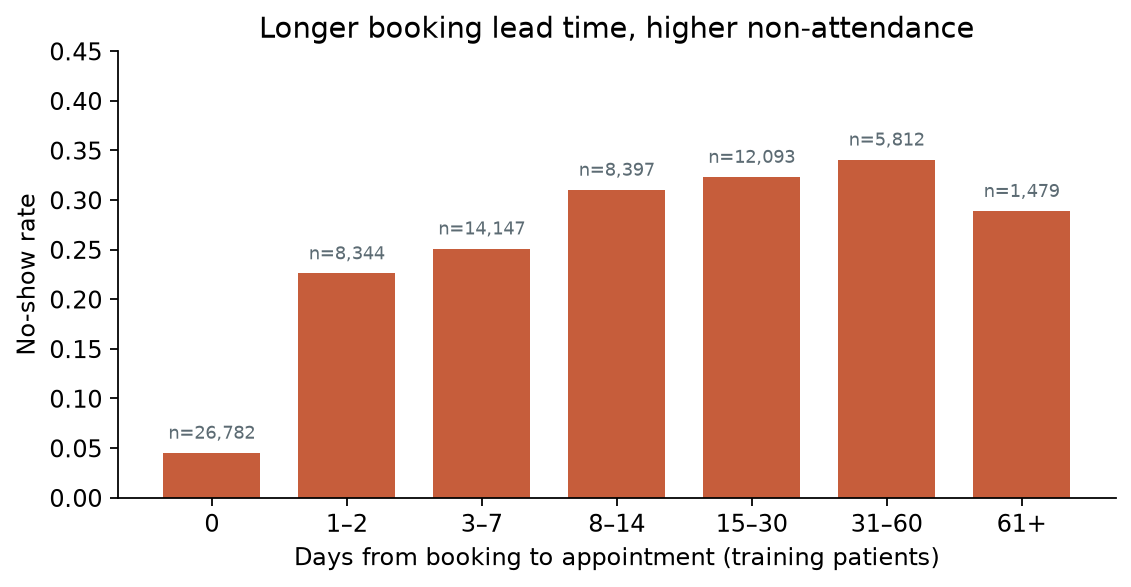

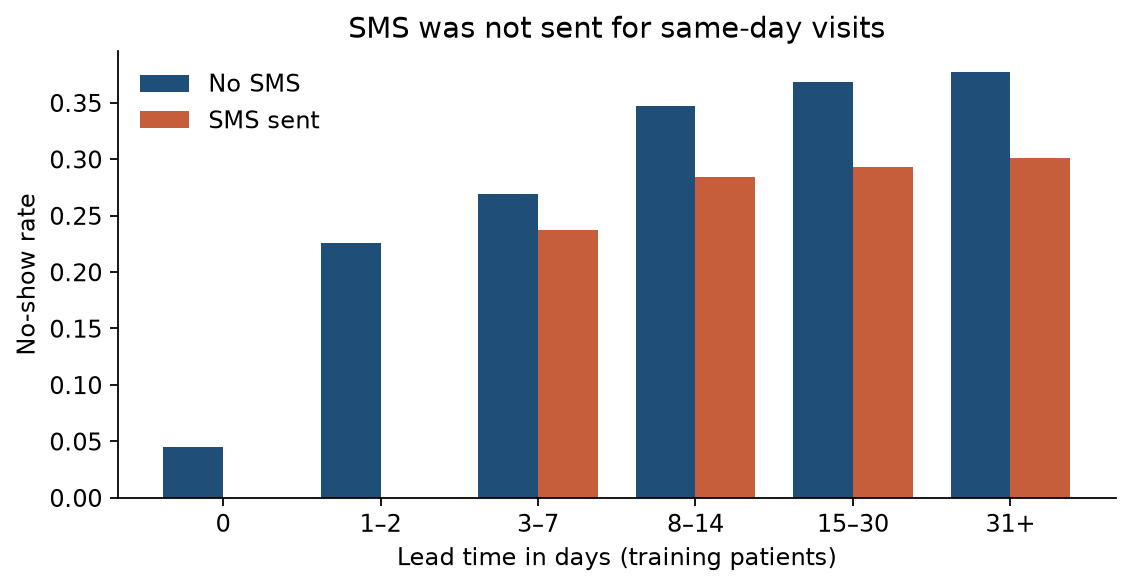

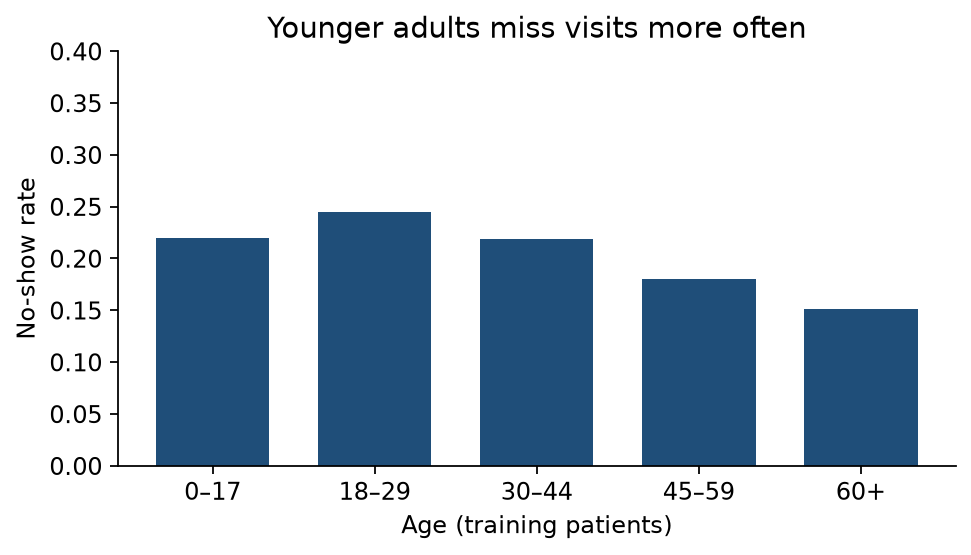

In [3]:
from IPython.display import Image, display

for name in ["class_balance.png", "noshow_by_lead.png", "sms_by_lead.png", "noshow_by_age.png"]:
    display(Image(filename=str(FIG_DIR / name)))

Same-day visits miss at about 4.5 percent. A wait of one or two days is already above 20 percent, and waits of two to four weeks sit near 32 percent. Inside a lead-time bin, the group that received an SMS has a **lower** no-show rate than the group that did not. The crude comparison runs the other way only because short-notice visits never get a message. Younger adults miss more often than patients aged 60 and above, which matches the determinant reviews and shows up later as unequal recall.

## Sixteen experiments

Validation chooses hyperparameters and the F1 threshold. The test patients are scored after that lock. ROC-AUC and average precision are the ranking metrics. Accuracy is reported so the majority baseline is visible; it is not how models are selected.

| ID | What changed |
| --- | --- |
| E0 | Always predict attendance |
| E1 | Score = lead time only |
| E2 | Logistic regression, demographics and clinical flags |
| E3 | Add scheduling features, class-balanced |
| E4 | Add personal history and neighbourhood codes |
| E5 | Choose `C` on validation ROC-AUC |
| E6 | Forest, depth 8, leaf 20 |
| E7 | Forest, unlimited depth, leaf 1 (variance probe) |
| E8 | Forest, depth 16, leaf 5 |
| E9 | Histogram gradient boosting, class-weighted |
| E10 | Same booster, no class weights |
| E11 | Linear SVM, `C` chosen on validation |
| E12 | RBF SVM on 8,000 training rows |
| E13 | Shallow MLP, `tf.data`, no class weights |
| E14 | Deeper MLP, dropout, batch norm, class weights |
| E15 | Functional MLP with a neighbourhood embedding |

E15 does not receive the hand-built neighbourhood rate. The embedding has to learn location itself. Offline Weights & Biases runs for each id are under `artifacts/wandb/`.

In [4]:
if RETRAIN:
    from clinic_noshow.experiments import run_all
    run_all()

table = pd.read_csv(METRIC_DIR / "experiment_table.csv")
view = table[[
    "id", "model", "features", "val_roc_auc", "val_pr_auc",
    "test_roc_auc", "test_pr_auc", "test_precision", "test_recall",
    "test_f1", "auc_gap", "fit_seconds",
]].copy()
for column in view.columns:
    if column not in {"id", "model", "features"}:
        view[column] = view[column].map(lambda x: round(float(x), 3))
view

,id,model,features,val_roc_auc,val_pr_auc,test_roc_auc,test_pr_auc,test_precision,test_recall,test_f1,auc_gap,fit_seconds
0,E0,Majority class (always attend),none,0.500,0.202,0.500,0.201,0.000,0.000,0.000,0.000,0.00
1,E1,Lead-time rule,lead_days,0.698,0.304,0.696,0.306,0.286,0.866,0.430,0.001,0.00
2,E2,Logistic regression,demographic,0.544,0.219,0.539,0.215,0.211,0.834,0.337,0.006,0.09
3,E3,Logistic regression,scheduling,0.722,0.349,0.713,0.334,0.313,0.731,0.438,0.003,0.22
4,E4,Logistic regression,full,0.734,0.384,0.726,0.373,0.310,0.761,0.441,0.001,0.26
5,E5,Logistic regression,full,0.734,0.384,0.726,0.373,0.310,0.761,0.441,0.001,1.06
6,E6,Random forest,full,0.747,0.416,0.743,0.401,0.326,0.744,0.454,0.019,2.60
7,E7,Random forest,full,0.749,0.410,0.737,0.389,0.314,0.762,0.445,0.250,1.43
8,E8,Random forest,full,0.754,0.425,0.746,0.403,0.322,0.783,0.457,0.131,5.01
9,E9,HistGradientBoosting,full,0.757,0.432,0.748,0.410,0.336,0.693,0.452,0.013,0.47


### How to read the table

E0 has ROC-AUC 0.5 and recall 0. That is the accuracy trap: test accuracy near 0.80 with no no-shows detected.

E2, demographics and diagnosis flags only, is barely above chance (test ROC-AUC about 0.54). E1, lead time alone, jumps to about 0.70. E3 and E4 add the rest of the booking record and personal history and land near 0.73. The `C` grid in E5 does not move validation ROC-AUC at three decimal places, so the linear model is not starved of regularisation and not helped by removing it.

E7 is the deliberate overfit. The training ROC-AUC is 0.999 and the gap is 0.25. Test ROC-AUC then falls below the shallow forest E6. Depth bought memorisation of training visits, not a better ranking of new patients. E10, unweighted boosting, is the best traditional validation ROC-AUC (about 0.758) and the selected traditional model. E9 matches it on the test ROC-AUC and loses on calibration, which the reliability plot shows.

E11 ties logistic regression. E12, the kernel SVM on a subsample, is worse. Discarding training patients cost more than the nonlinear boundary returned.

E13–E15 sit in a narrow band just under the booster. E15 is the best network and the selected deep model. Extra epochs do not pull it ahead. On this table the label is mostly a step in lead time, which a tree cuts directly.

## Learning curves, ranking, and calibration

The logistic curve is the bias picture: training and cross-validation lie on top of each other, and more rows from the same six weeks do not help. The constrained forest narrows its gap slightly and does not raise the cross-validated ceiling. The neural losses do not diverge. Class-weighted nets sit on a higher loss scale because the objective changed, not because the step size exploded. Their validation ROC-AUC flattens below 0.75.

The ROC plot makes several models look similar. The precision–recall plot is the one that matches a reminder budget: precision stays well below one half at the recalls a clinic would want. The reliability plot is why E10 is preferred to E5 and E15 even when ROC-AUC is close. Class weights push predicted probabilities above the observed rate. A cutoff of 0.5 on those models does not mean an even chance.

learning_curve_logreg.png


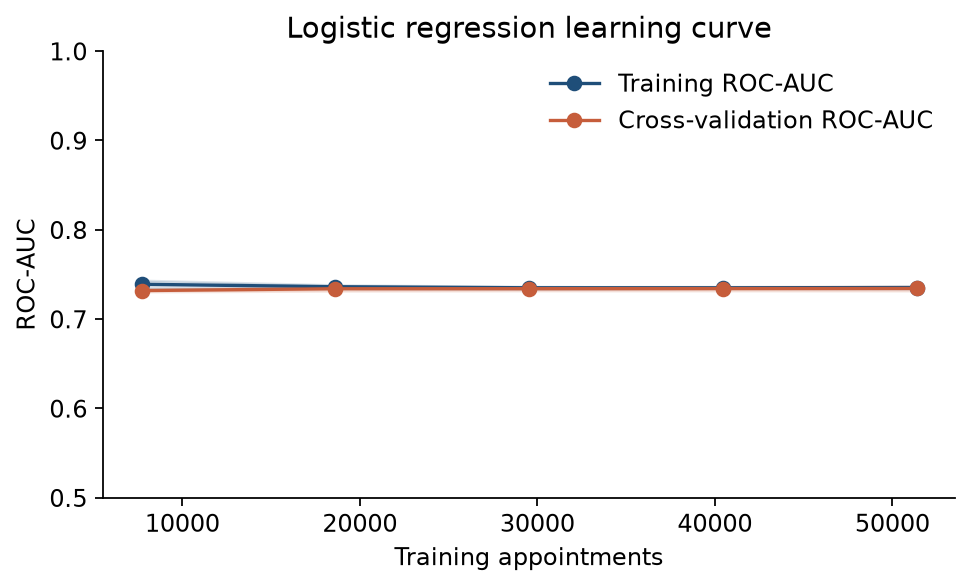

learning_curve_forest.png


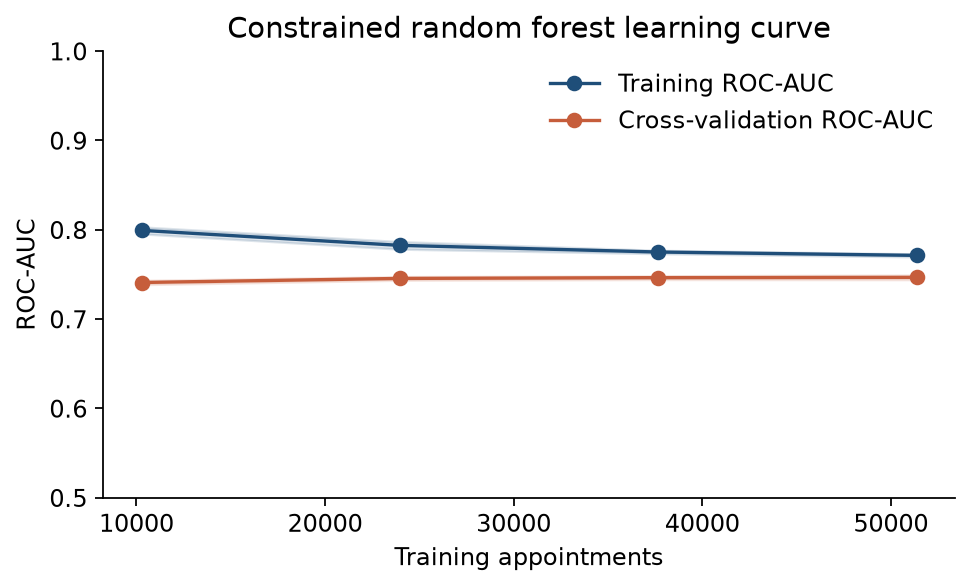

dl_learning_curves.png


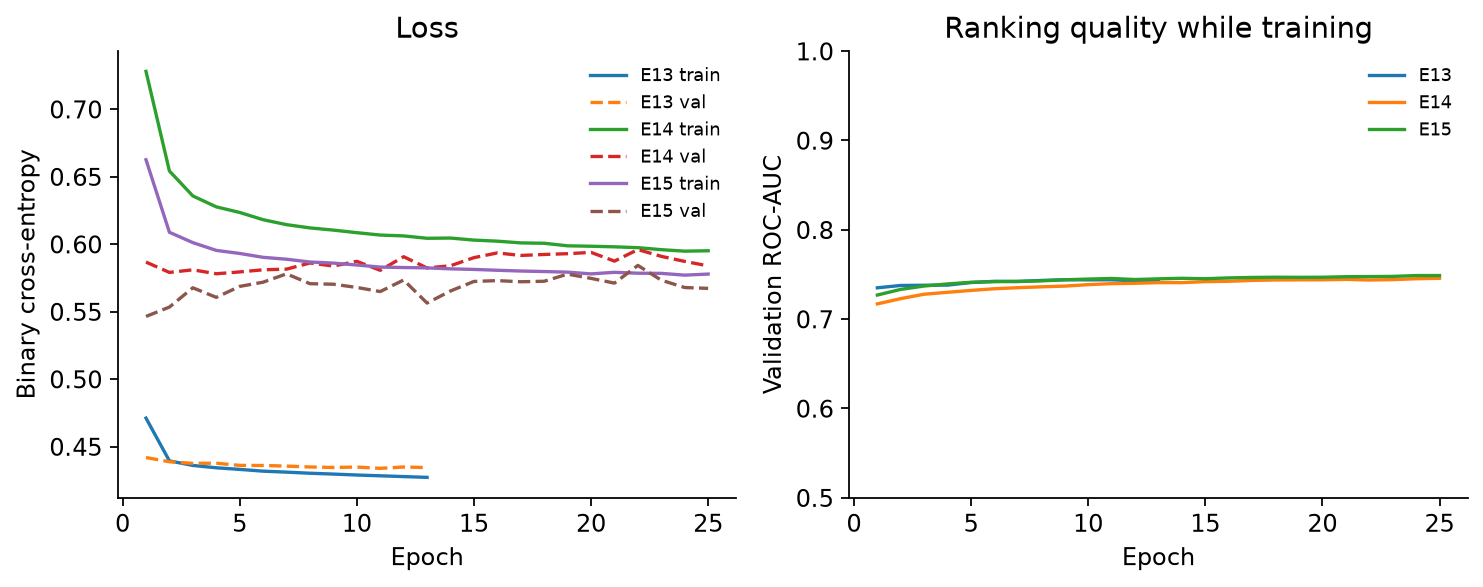

roc_test.png


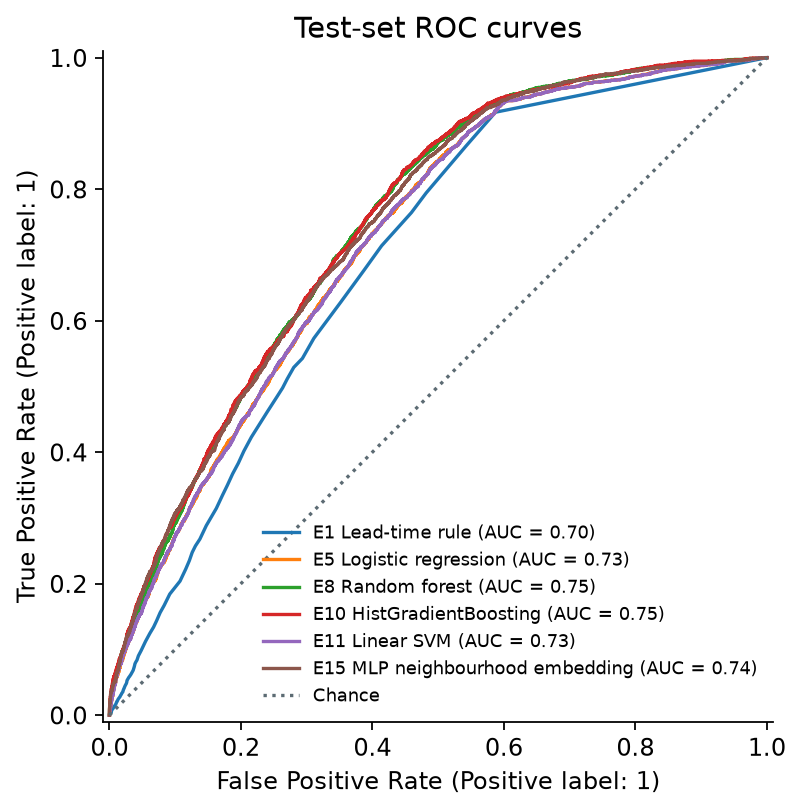

pr_test.png


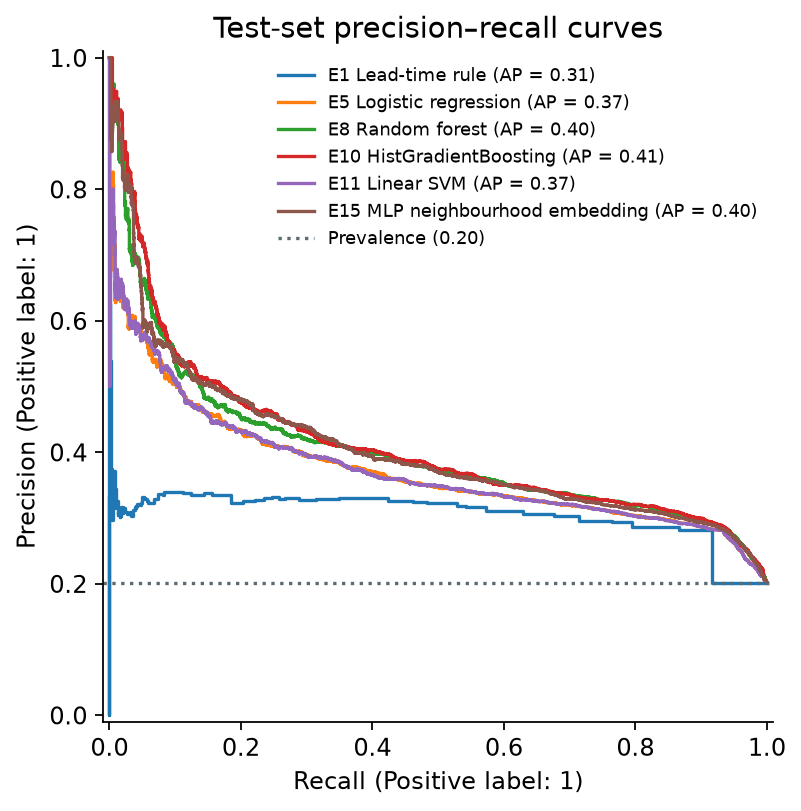

calibration_test.png


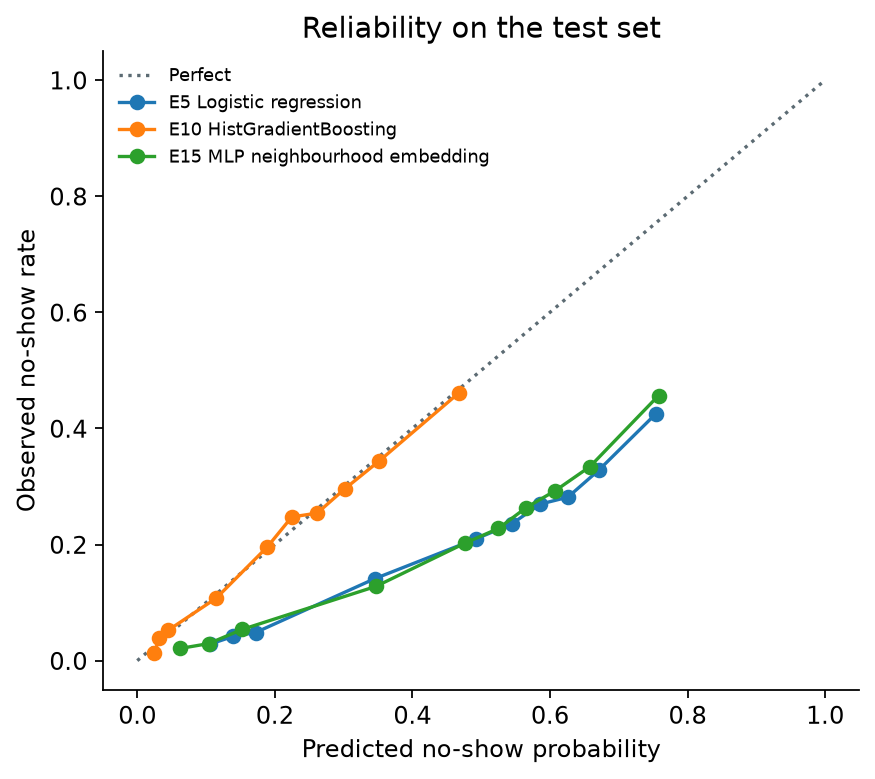

logreg_coefficients.png


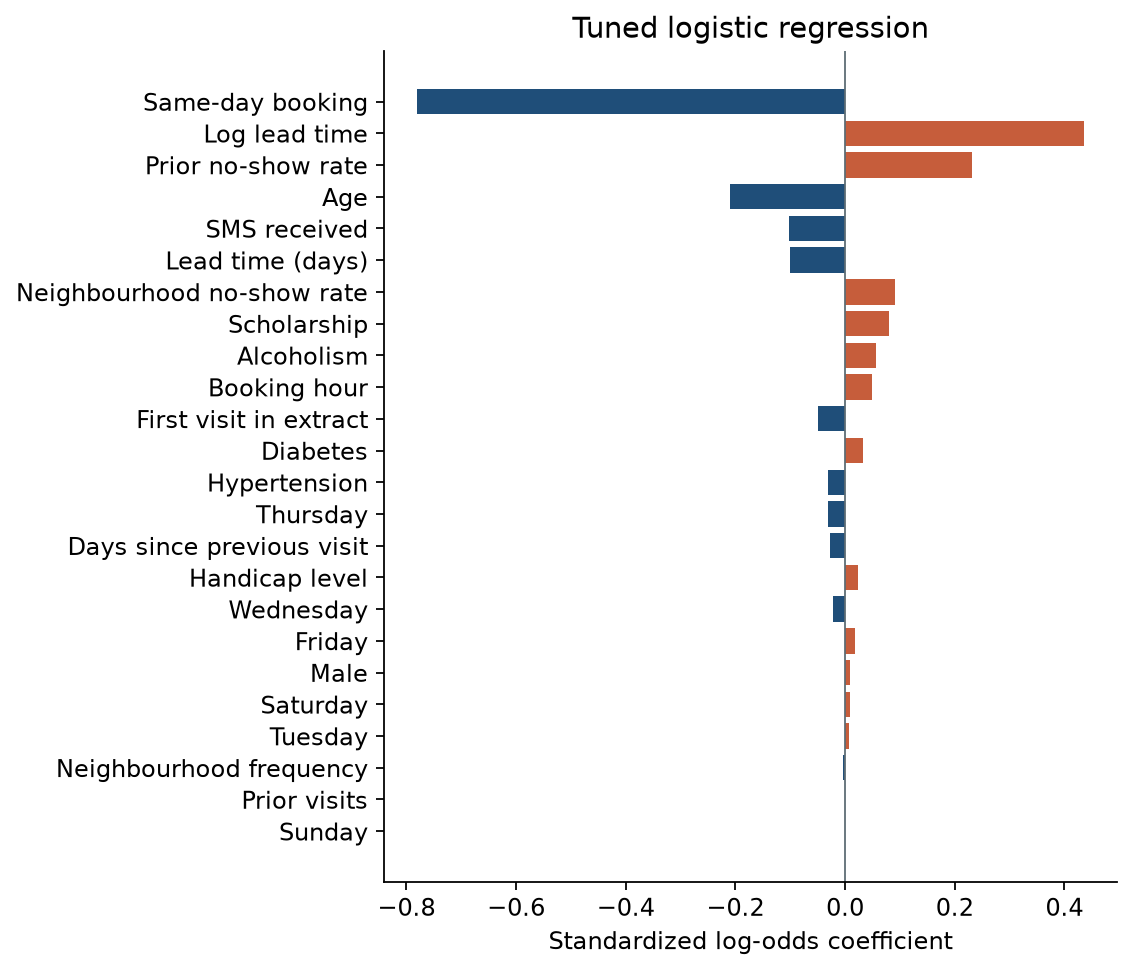

permutation_importance.png


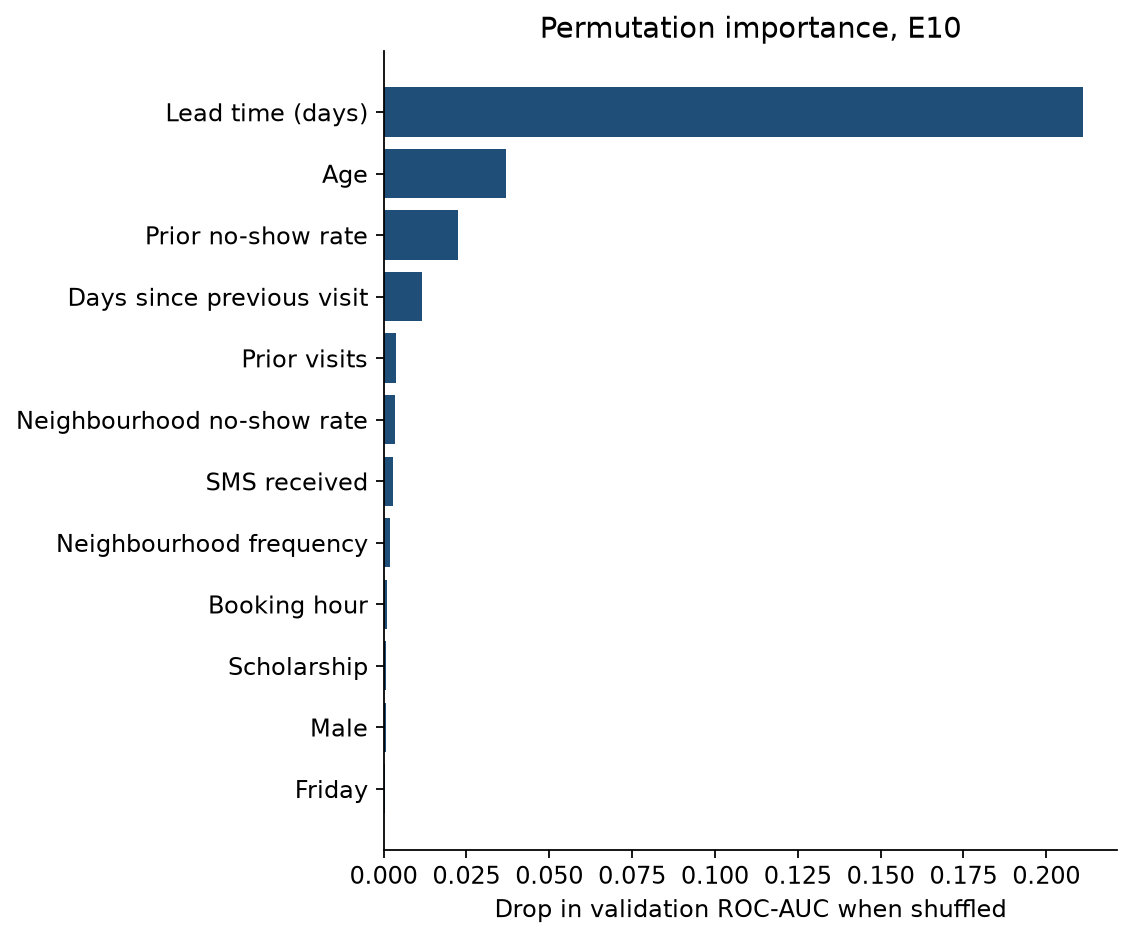

In [5]:
for name in [
    "learning_curve_logreg.png",
    "learning_curve_forest.png",
    "dl_learning_curves.png",
    "roc_test.png",
    "pr_test.png",
    "calibration_test.png",
    "logreg_coefficients.png",
    "permutation_importance.png",
]:
    print(name)
    display(Image(filename=str(FIG_DIR / name)))

Permutation importance on the selected booster is mostly lead time. Shuffling that column removes on the order of 0.20 ROC-AUC. Age and prior no-show rate are next. SMS, sex, and scholarship barely move the score once lead time is present.

The logistic coefficients need the same caution. Same-day booking and log lead time take large coefficients of opposite sign, and the raw day count is small, because those three columns are one mechanism. Do not read the negative raw-day coefficient as "waiting longer prevents no-shows." The permutation result rules that out. Prior no-show rate is positive and age is negative, which is the cleaner pair: a worse personal history raises risk, and older patients have lower risk after the other columns are held fixed. The SMS coefficient is slightly protective once lead time is in the model, matching the stratified bar chart rather than the crude gap.

## Operating points and who is missed

The F1 threshold was locked on validation. For the unweighted booster it sits near 0.23, because a calibrated model of a 20 percent event rarely outputs large probabilities. At that point the test confusion matrix catches about three quarters of no-shows and flags a large share of attenders. The embedding network, trained with class weights, uses a threshold near 0.5 and produces almost the same counts. The architecture did not change the error budget.

The policy table applies other validation-locked rules to the booster's test probabilities. The overbooking rule (false positives five times as costly as false negatives) drives recall under 2 percent at precision near 0.9. The top 20 percent of scores is the rule that matches a limited reminder budget: precision near 0.40 and recall near 0.41.

Policies (thresholds locked on validation, metrics on test)


,model,policy,threshold_locked_on_validation,precision,recall,f1,overbook_cost_per_1000,remind_cost_per_1000
0,E10,f1,0.225,0.329,0.733,0.454,1555.423,461.079
1,E10,overbook,0.775,0.908,0.018,0.034,199.271,592.790
2,E10,remind,0.250,0.344,0.653,0.451,1321.655,459.524
3,E10,capacity20,0.321,0.399,0.412,0.406,741.719,479.134
4,E10,default,0.500,0.635,0.066,0.120,225.936,570.668


Test slices for the selected traditional model at its F1 threshold


,slice,n,noshow_rate,recall,precision,roc_auc
0,Lead 0 days,5796,0.048,0.161,0.469,0.713
1,Lead 1–7 days,4848,0.238,0.618,0.283,0.599
2,Lead 8–30 days,4528,0.310,0.884,0.342,0.625
3,Lead 31+ days,1554,0.337,0.891,0.374,0.651
4,Age 0–17,4107,0.215,0.865,0.334,0.758
5,Age 18–39,4688,0.238,0.890,0.356,0.739
6,Age 40–59,4610,0.180,0.623,0.295,0.729
7,Age 60+,3321,0.160,0.360,0.292,0.711
8,Women,10914,0.200,0.739,0.330,0.752
9,Men,5812,0.203,0.723,0.329,0.742


confusion_best_traditional.png


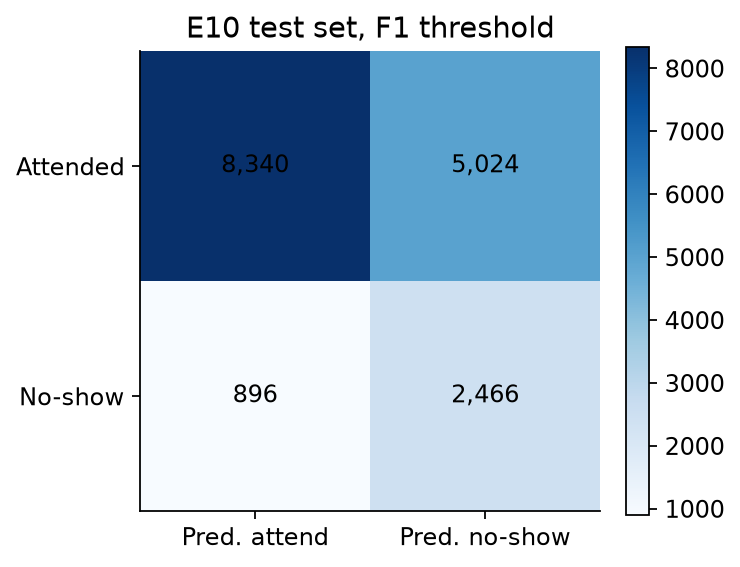

confusion_best_deep.png


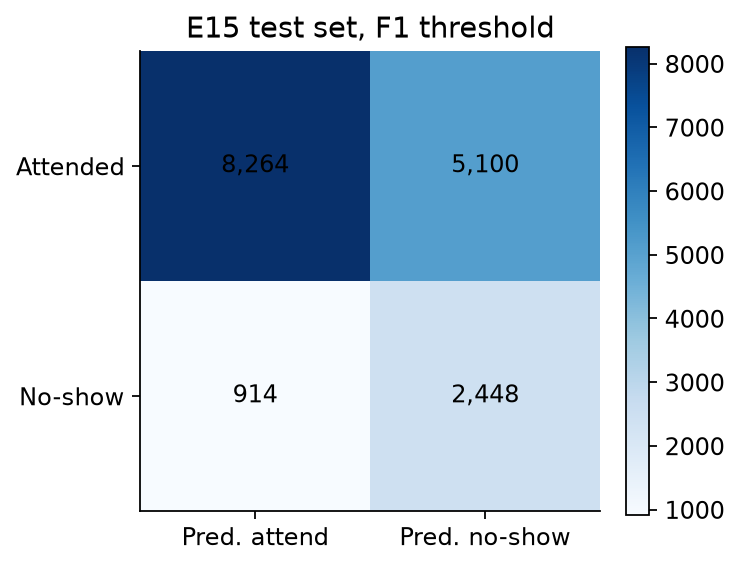

threshold_tradeoff_val.png


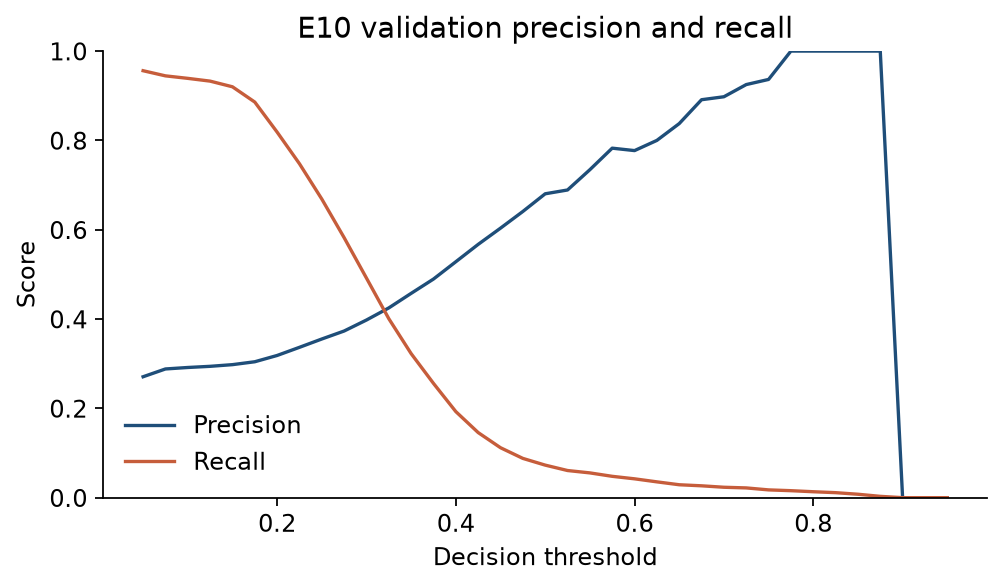

slice_recall_test.png


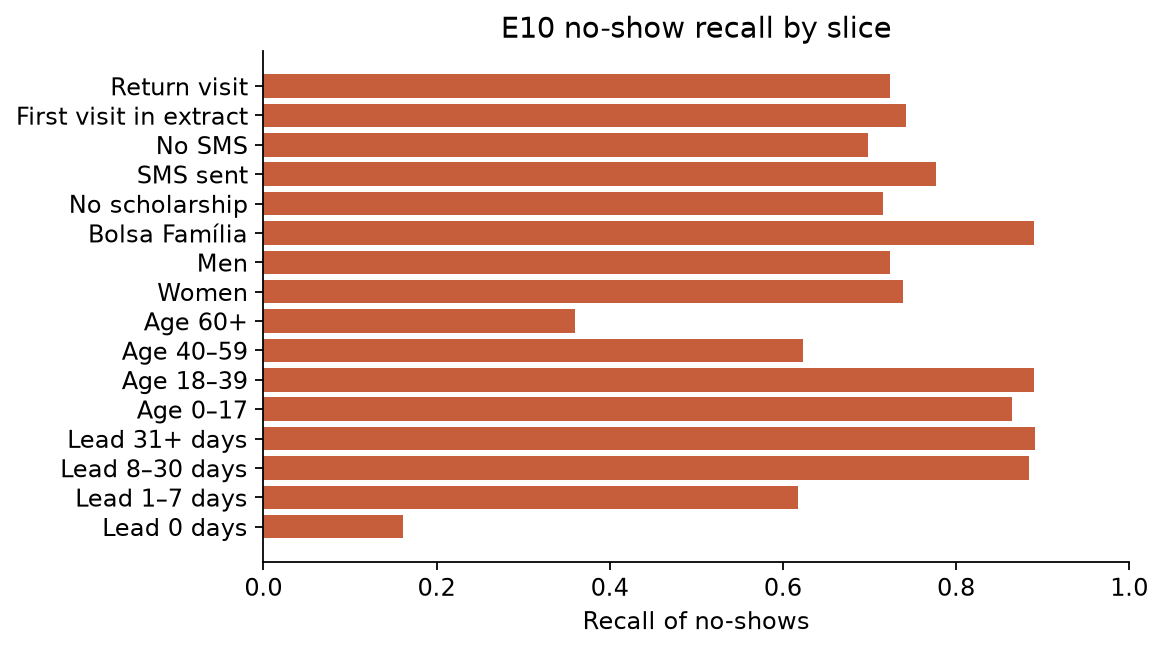

In [6]:
print("Policies (thresholds locked on validation, metrics on test)")
display(pd.read_csv(METRIC_DIR / "policy_comparison_test.csv").round(3))
print("Test slices for the selected traditional model at its F1 threshold")
display(pd.read_csv(METRIC_DIR / "error_slices_test.csv").round(3))
for name in [
    "confusion_best_traditional.png",
    "confusion_best_deep.png",
    "threshold_tradeoff_val.png",
    "slice_recall_test.png",
]:
    print(name)
    display(Image(filename=str(FIG_DIR / name)))

Same-day no-shows are rarely flagged. They are uncommon, and a global F1 threshold will not spend flags on a 5 percent base rate. Recall is high once the wait is longer than a week, which is another way of saying the model rediscovers lead time. Patients aged 60 and above have recall near 0.36, against near 0.89 for adults under 40. The score still ranks inside the older slice (ROC-AUC near 0.71), but one threshold does not give those no-shows an equal chance of a reminder. Sex gaps are small. First visits, which have no personal history, are only a little harder than return visits.

## What I would and would not do with this score

I would use E10 as a ranked reminder list, contacting the top fifth of bookings if staff time or airtime is limited. I would not auto-overbook at the F1 threshold. I would not copy either threshold into a clinic whose no-show rate is closer to the African averages in the reviews than to Vitória's 20 percent. Those clinics need their own labels. The design that does transfer is the one in this notebook: store the booking time, store the outcome, keep a patient's history out of other patients' training rows, and pick the threshold for the action rather than for accuracy.

Saved weights are `artifacts/models/best_traditional.joblib` and `artifacts/models/best_deep.keras`, chosen by validation ROC-AUC inside each family. A copy for the Drive upload lives under `deliverables/`.